In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn joblib streamlit ipykernel

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [3]:
df= pd.read_csv("Life Expectancy Data.csv")
df.head(10)

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
5,Afghanistan,2010,Developing,58.8,279.0,74,0.01,79.679367,66.0,1989,...,66.0,9.20,66.0,0.1,553.328940,2883167.0,18.4,18.4,0.448,9.2
6,Afghanistan,2009,Developing,58.6,281.0,77,0.01,56.762217,63.0,2861,...,63.0,9.42,63.0,0.1,445.893298,284331.0,18.6,18.7,0.434,8.9
7,Afghanistan,2008,Developing,58.1,287.0,80,0.03,25.873925,64.0,1599,...,64.0,8.33,64.0,0.1,373.361116,2729431.0,18.8,18.9,0.433,8.7
8,Afghanistan,2007,Developing,57.5,295.0,82,0.02,10.910156,63.0,1141,...,63.0,6.73,63.0,0.1,369.835796,26616792.0,19.0,19.1,0.415,8.4
9,Afghanistan,2006,Developing,57.3,295.0,84,0.03,17.171518,64.0,1990,...,58.0,7.43,58.0,0.1,272.563770,2589345.0,19.2,19.3,0.405,8.1


In [4]:
print(df.shape)
df.info()

(2938, 22)
<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [5]:
print(df.columns.tolist())


['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years', ' thinness 5-9 years', 'Income composition of resources', 'Schooling']


In [6]:
df.isnull().sum().sort_values(ascending=False)

Population                         652
Hepatitis B                        553
GDP                                448
Total expenditure                  226
Alcohol                            194
Income composition of resources    167
Schooling                          163
 thinness  1-19 years               34
 thinness 5-9 years                 34
 BMI                                34
Diphtheria                          19
Polio                               19
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Status                               0
Country                              0
Year                                 0
under-five deaths                    0
Measles                              0
percentage expenditure               0
 HIV/AIDS                            0
dtype: int64

In [7]:
df.columns =(df.columns.str.strip().str.replace(r'\s+', '_').str.lower().str.replace(' ', '_').str.replace('-','_').str.replace('/','_')
             )
print(df.columns.tolist())

['country', 'year', 'status', 'life_expectancy', 'adult_mortality', 'infant_deaths', 'alcohol', 'percentage_expenditure', 'hepatitis_b', 'measles', 'bmi', 'under_five_deaths', 'polio', 'total_expenditure', 'diphtheria', 'hiv_aids', 'gdp', 'population', 'thinness__1_19_years', 'thinness_5_9_years', 'income_composition_of_resources', 'schooling']


In [8]:
print('Duplicate rows:', df.duplicated().sum())
missing = df.isnull().sum()
pd.DataFrame({'missing': missing, 'percent':(missing/len(df)*100).round(1)}).sort_values('missing', ascending=False)

Duplicate rows: 0


,missing,percent
population,652,22.2
hepatitis_b,553,18.8
gdp,448,15.2
total_expenditure,226,7.7
alcohol,194,6.6
income_composition_of_resources,167,5.7
schooling,163,5.5
thinness__1_19_years,34,1.2
thinness_5_9_years,34,1.2
bmi,34,1.2


In [9]:
print('before:',df.shape)
df=df.dropna(subset=['life_expectancy'])
print('After:',df.shape)

before: (2938, 22)
After: (2928, 22)


In [10]:
df=df.sort_values(['country', 'year']).reset_index(drop=True)
num_cols = df.select_dtypes(include='number').columns.drop(['year', 'life_expectancy'])
df[num_cols] = (df.groupby('country')[num_cols]
                .transform(lambda s: s.interpolate(limit_direction='both')))
df.isnull().sum().sort_values(ascending=False).head(10)


population                         640
gdp                                400
income_composition_of_resources    160
schooling                          160
hepatitis_b                        144
bmi                                 32
thinness__1_19_years                32
thinness_5_9_years                  32
total_expenditure                   32
alcohol                             16
dtype: int64

In [11]:
df.dtypes

country                                str
year                                 int64
status                                 str
life_expectancy                    float64
adult_mortality                    float64
infant_deaths                        int64
alcohol                            float64
percentage_expenditure             float64
hepatitis_b                        float64
measles                              int64
bmi                                float64
under_five_deaths                    int64
polio                              float64
total_expenditure                  float64
diphtheria                         float64
hiv_aids                           float64
gdp                                float64
population                         float64
thinness__1_19_years               float64
thinness_5_9_years                 float64
income_composition_of_resources    float64
schooling                          float64
dtype: object

In [12]:
df.columns = df.columns.str.replace('__', '_')
print(df.columns.tolist())


['country', 'year', 'status', 'life_expectancy', 'adult_mortality', 'infant_deaths', 'alcohol', 'percentage_expenditure', 'hepatitis_b', 'measles', 'bmi', 'under_five_deaths', 'polio', 'total_expenditure', 'diphtheria', 'hiv_aids', 'gdp', 'population', 'thinness_1_19_years', 'thinness_5_9_years', 'income_composition_of_resources', 'schooling']


In [13]:
df.select_dtypes(include='number').corr()['life_expectancy'].drop('life_expectancy').sort_values()

adult_mortality                   -0.696359
hiv_aids                          -0.556556
thinness_1_19_years               -0.477183
thinness_5_9_years                -0.471584
under_five_deaths                 -0.222529
infant_deaths                     -0.196557
measles                           -0.157586
population                        -0.021371
year                               0.170033
total_expenditure                  0.230900
hepatitis_b                        0.319101
percentage_expenditure             0.381864
alcohol                            0.402761
polio                              0.460142
gdp                                0.461511
diphtheria                         0.474818
bmi                                0.567694
income_composition_of_resources    0.724776
schooling                          0.751975
Name: life_expectancy, dtype: float64

In [14]:
df = df.drop(columns=['population'])
print(df.shape)

(2928, 21)


In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,2928.0,2007.500000,4.610560,2000.00000,2003.750000,2007.500000,2011.250000,2015.00000
life_expectancy,2928.0,69.224932,9.523867,36.30000,63.100000,72.100000,75.700000,89.00000
adult_mortality,2928.0,164.796448,124.292079,1.00000,74.000000,144.000000,228.000000,723.00000
infant_deaths,2928.0,30.407445,118.114450,0.00000,0.000000,3.000000,22.000000,1800.00000
alcohol,2912.0,4.528796,4.069668,0.01000,0.647500,3.630000,7.640000,17.87000
percentage_expenditure,2928.0,740.321185,1990.930605,0.00000,4.853964,65.611455,442.614322,19479.91161
hepatitis_b,2784.0,75.815374,28.593029,1.00000,66.000000,89.000000,96.000000,99.00000
measles,2928.0,2427.855874,11485.970937,0.00000,0.000000,17.000000,362.250000,212183.00000
bmi,2896.0,38.235394,19.959590,1.00000,19.300000,43.350000,56.100000,77.60000
under_five_deaths,2928.0,42.179303,160.700547,0.00000,0.000000,4.000000,28.000000,2500.00000


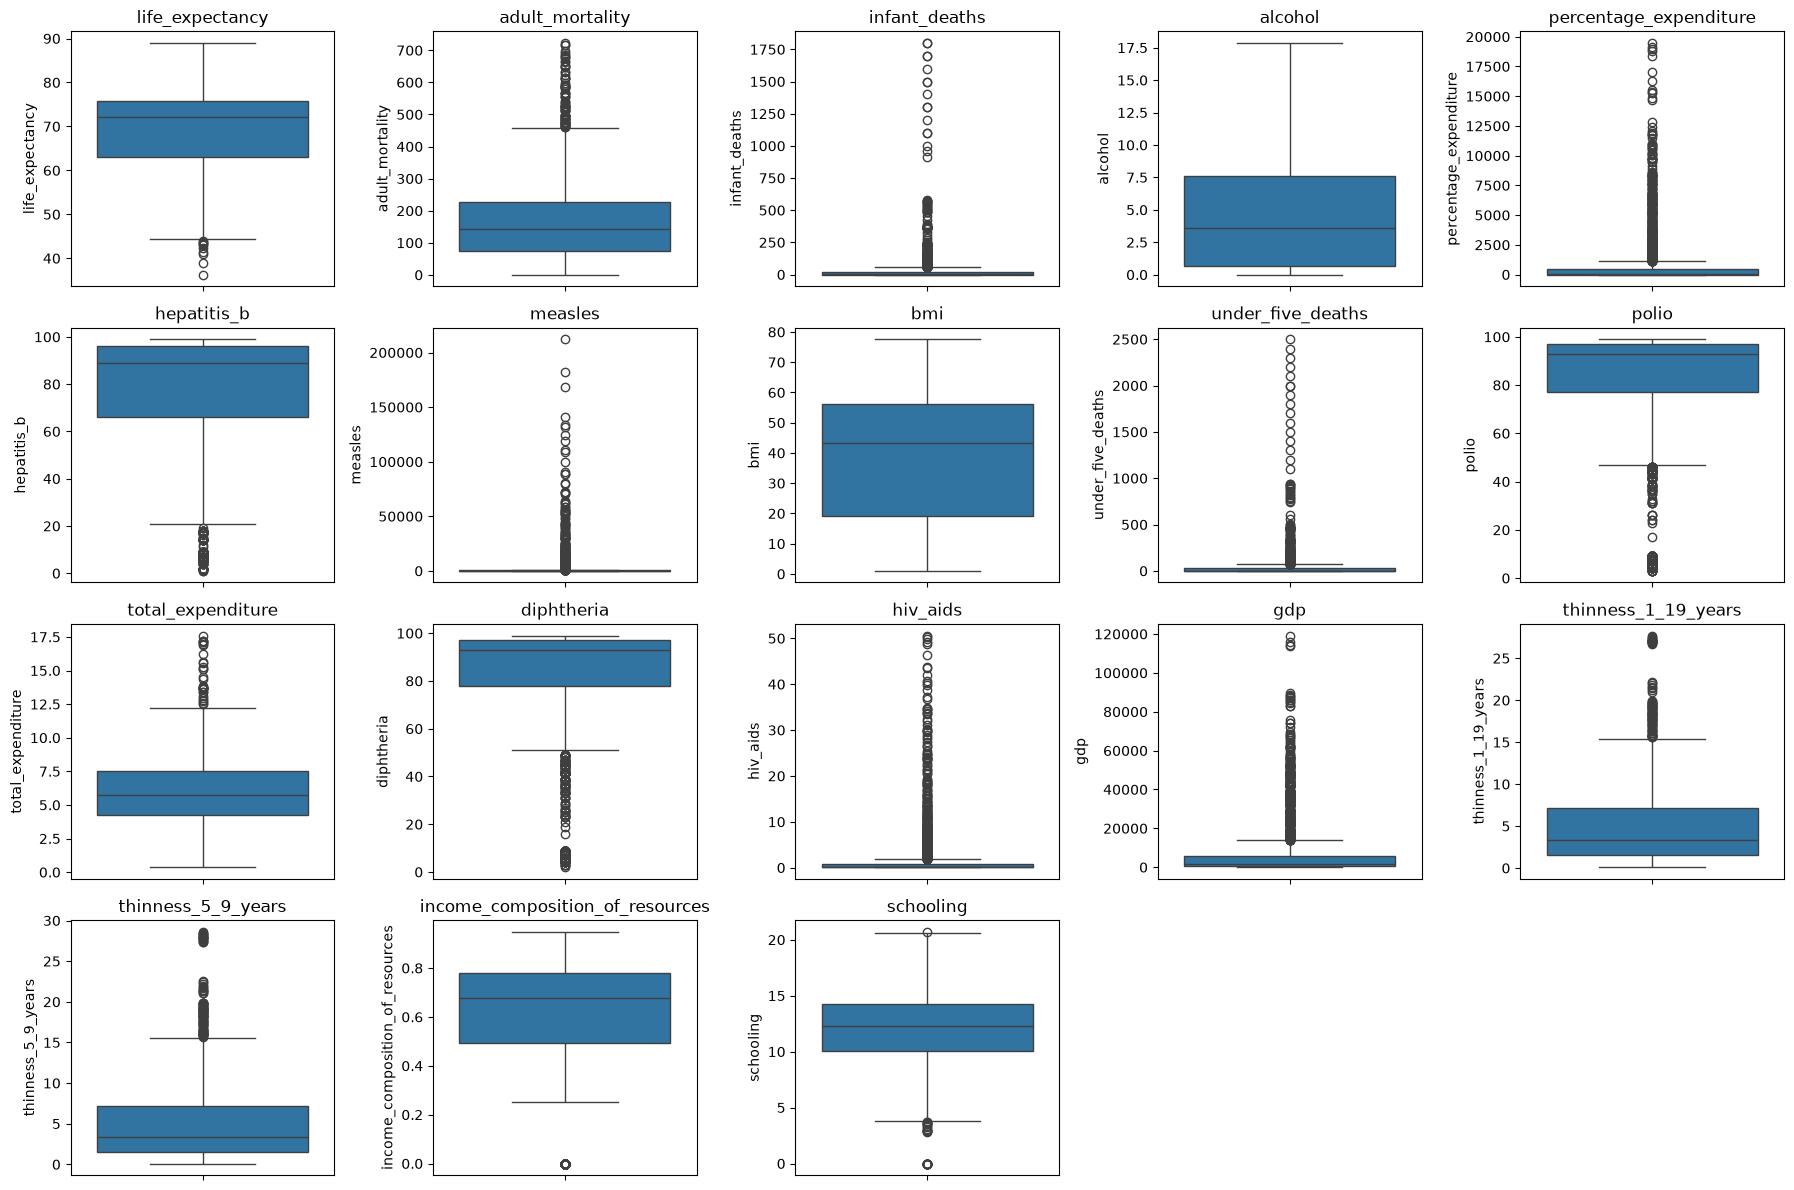

In [16]:
num = df.select_dtypes(include='number').columns.drop('year')

fig, axes = plt.subplots(4, 5, figsize=(18, 12))
for ax, col in zip(axes.ravel(), num):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(num):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [17]:
print('bmi < 10                :', (df['bmi'] < 10).sum())
print('bmi > 50                :', (df['bmi'] > 50).sum())
print('schooling == 0          :', (df['schooling'] == 0).sum())
print('income_composition == 0 :', (df['income_composition_of_resources'] == 0).sum())
print('adult_mortality == 0    :', (df['adult_mortality'] == 0).sum())

bmi < 10                : 282
bmi > 50                : 1132
schooling == 0          : 26
income_composition == 0 : 130
adult_mortality == 0    : 0


In [18]:
df.loc[df['bmi'] < 10, 'bmi'] = np.nan

for col in ['income_composition_of_resources', 'schooling']:
    df[col] = df[col].replace(0, np.nan)

for col in ['bmi', 'income_composition_of_resources', 'schooling']:
    df[col] = df.groupby('country')[col].transform(
        lambda s: s.interpolate(limit_direction='both')
    )

df.isnull().sum().sort_values(ascending=False).head(10)

gdp                                400
schooling                          160
income_composition_of_resources    160
hepatitis_b                        144
total_expenditure                   32
thinness_1_19_years                 32
bmi                                 32
thinness_5_9_years                  32
alcohol                             16
country                              0
dtype: int64

In [19]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

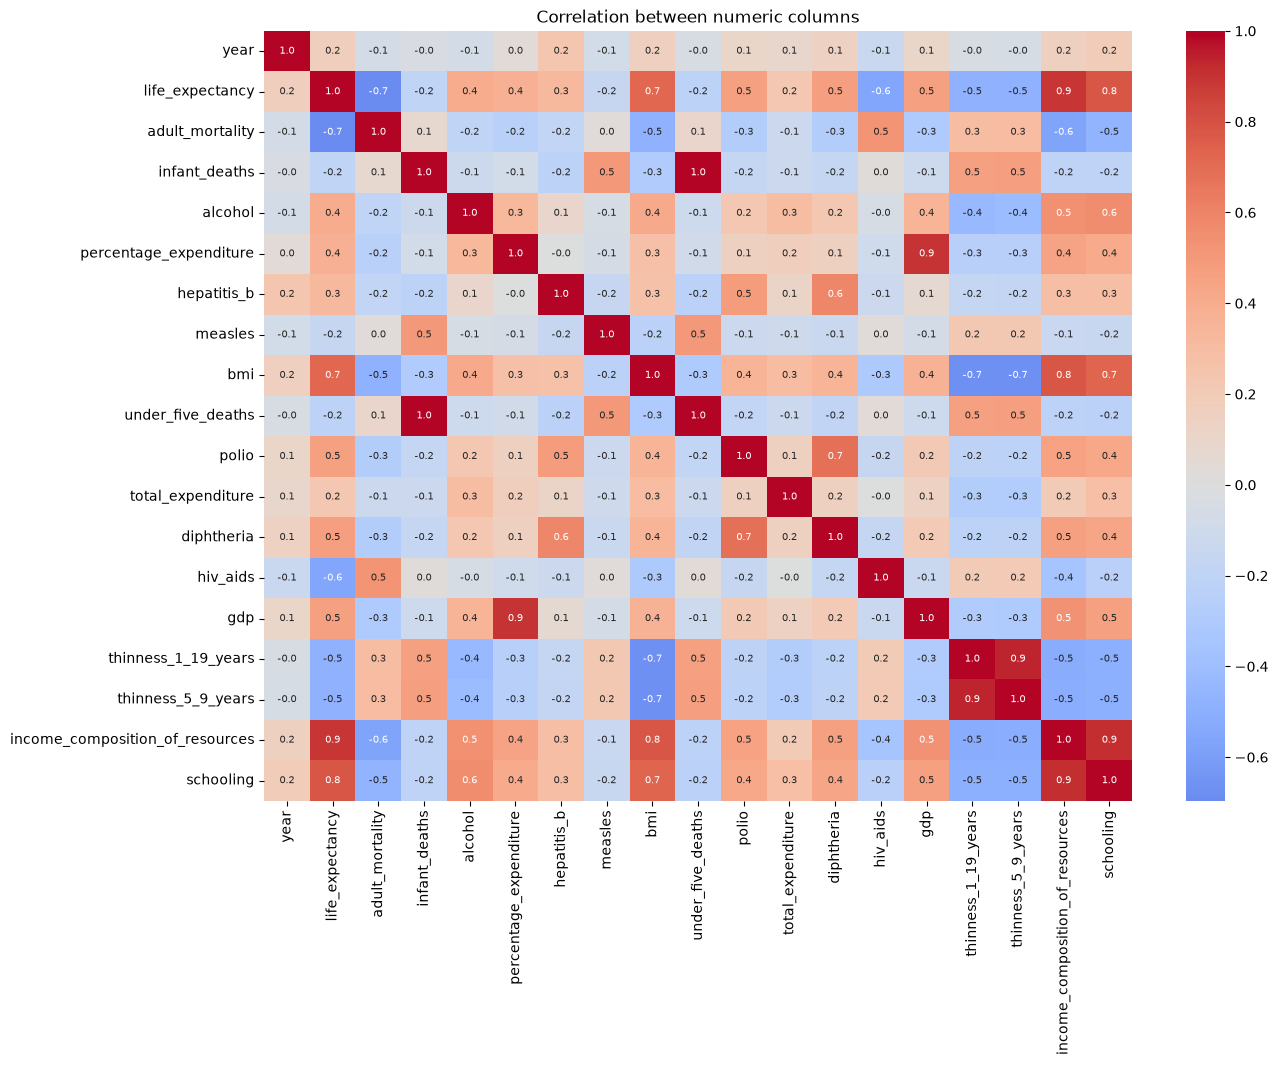

In [20]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, fmt='.1f',
            annot_kws={'size': 7}, cmap='coolwarm', center=0)
plt.title('Correlation between numeric columns')
plt.show()

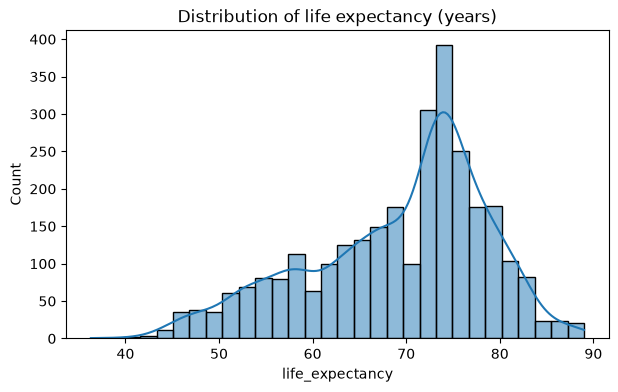

In [21]:
plt.figure(figsize=(7, 4))
sns.histplot(df['life_expectancy'], bins=30, kde=True)
plt.title('Distribution of life expectancy (years)')
plt.show()

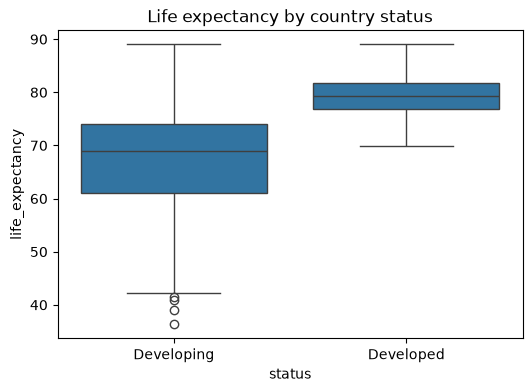

In [22]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='status', y='life_expectancy')
plt.title('Life expectancy by country status')
plt.show()

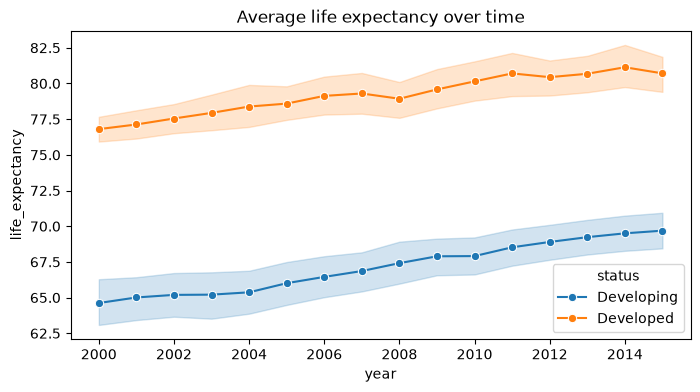

In [23]:
plt.figure(figsize=(8, 4))
sns.lineplot(data=df, x='year', y='life_expectancy', hue='status', marker='o')
plt.title('Average life expectancy over time')
plt.show()

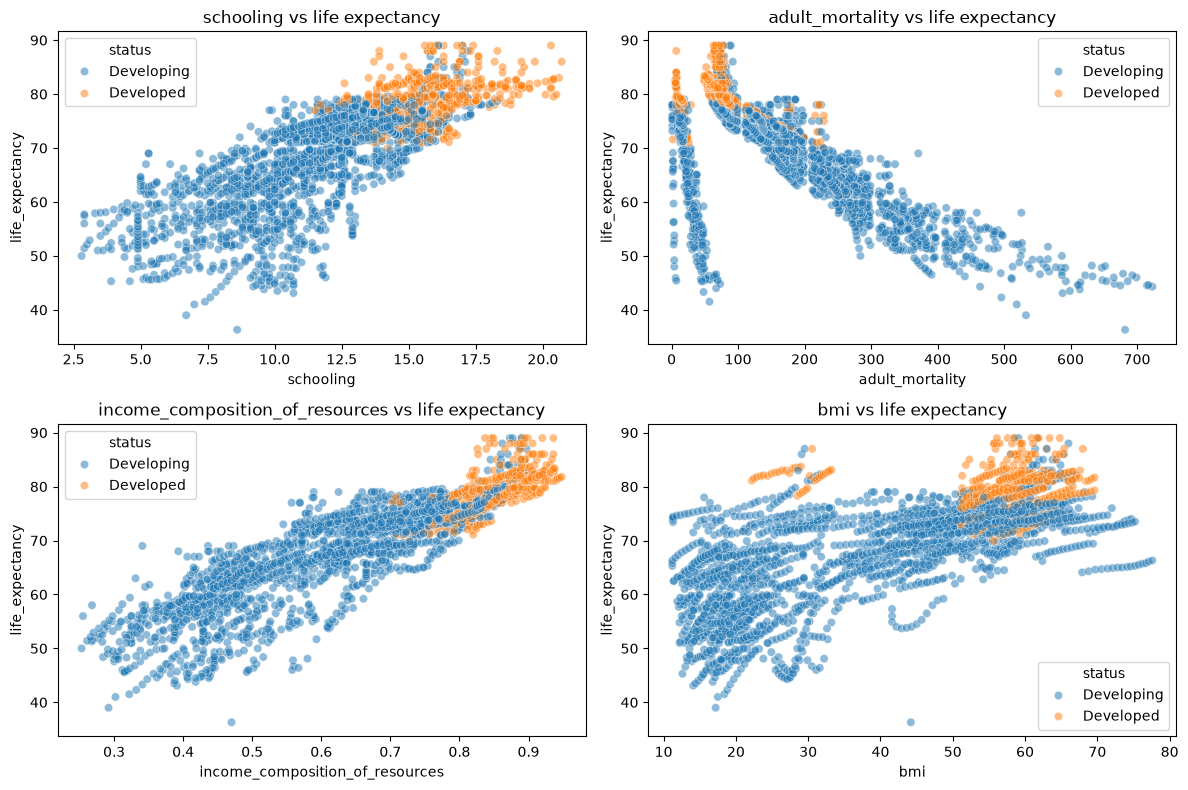

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ['schooling', 'adult_mortality',
                                  'income_composition_of_resources', 'bmi']):
    sns.scatterplot(data=df, x=col, y='life_expectancy', hue='status', alpha=0.5, ax=ax)
    ax.set_title(f'{col} vs life expectancy')
plt.tight_layout()
plt.show()

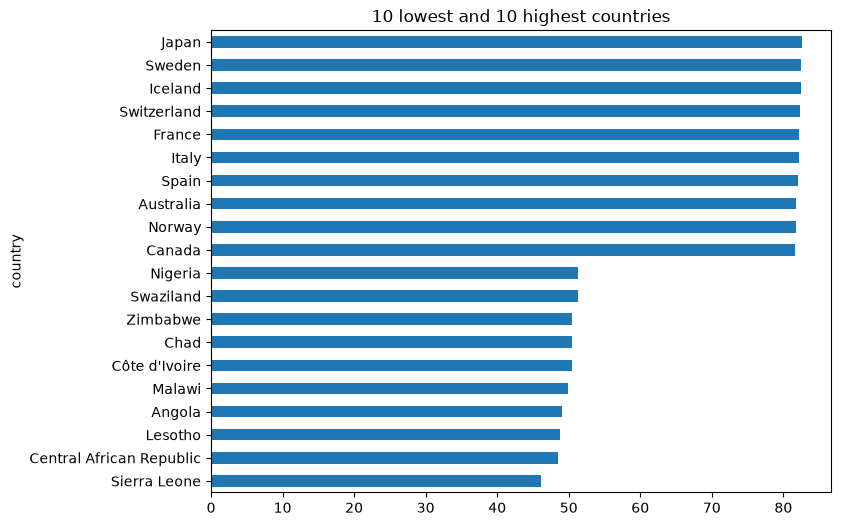

In [25]:
avg = df.groupby('country')['life_expectancy'].mean().sort_values()
pd.concat([avg.head(10), avg.tail(10)]).plot(kind='barh', figsize=(8, 6),
                                             title='10 lowest and 10 highest countries')
plt.show()

In [26]:
data = df.copy()

# 1. text -> number
print(data['status'].value_counts())
data['status'] = data['status'].map({'Developing': 0, 'Developed': 1})

# 2. new feature: average of the three vaccination columns
data['vaccine_avg'] = data[['hepatitis_b', 'polio', 'diphtheria']].mean(axis=1)
data = data.drop(columns=['hepatitis_b', 'polio', 'diphtheria'])

# 3. log transform for skewed columns
skew_cols = ['measles', 'infant_deaths', 'under_five_deaths',
             'gdp', 'percentage_expenditure', 'hiv_aids']
print(data[skew_cols].skew().round(1))        # big numbers = very skewed
for col in skew_cols:
    data[col + '_log'] = np.log1p(data[col])
data = data.drop(columns=skew_cols)

data.head()

status
Developing    2416
Developed      512
Name: count, dtype: int64
measles                   9.4
infant_deaths             9.8
under_five_deaths         9.5
gdp                       3.2
percentage_expenditure    4.6
hiv_aids                  5.4
dtype: float64


,country,year,status,life_expectancy,adult_mortality,alcohol,bmi,total_expenditure,thinness_1_19_years,thinness_5_9_years,income_composition_of_resources,schooling,vaccine_avg,measles_log,infant_deaths_log,under_five_deaths_log,gdp_log,percentage_expenditure_log,hiv_aids_log
0,Afghanistan,2000,0,54.8,321.0,0.01,12.2,8.20,2.3,2.5,0.338,5.5,36.666667,8.784622,4.488636,4.812184,4.749790,2.435800,0.09531
1,Afghanistan,2001,0,55.3,316.0,0.01,12.6,7.80,2.1,2.4,0.340,5.9,43.666667,9.078294,4.488636,4.812184,4.774887,2.448824,0.09531
2,Afghanistan,2002,0,56.2,3.0,0.01,13.0,7.76,19.9,2.2,0.341,6.2,45.333333,7.818832,4.488636,4.812184,5.240932,2.884094,0.09531
3,Afghanistan,2003,0,56.7,295.0,0.01,13.4,8.82,19.7,19.9,0.373,6.5,49.000000,6.683361,4.477337,4.812184,5.296959,2.492300,0.09531
4,Afghanistan,2004,0,57.0,293.0,0.02,13.8,8.79,19.5,19.7,0.381,6.8,25.666667,6.146329,4.477337,4.795791,5.394270,2.790924,0.09531


In [27]:
groups = data['country']
X = data.drop(columns=['country', 'life_expectancy'])
Y = data['life_expectancy']

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, Y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
Y_train, Y_test = Y.iloc[train_idx], Y.iloc[test_idx]

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Countries in both train and test:', len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Train: (2336, 17)  Test: (592, 17)
Countries in both train and test: 0


In [28]:
def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f'{name}: MAE={mae:.2f} years  RMSE={rmse:.2f} years  R2={r2:.3f}')
    return {'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2}

lin_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])
lin_pipe.fit(X_train, Y_train)
res_lin = report('Linear Regression', Y_test, lin_pipe.predict(X_test))

rf_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))
])
rf_pipe.fit(X_train, Y_train)
res_rf = report('Random Forest', Y_test, rf_pipe.predict(X_test))

knn_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor(n_neighbors=5))
])
knn_pipe.fit(X_train, Y_train)
res_knn = report('KNN', Y_test, knn_pipe.predict(X_test))

svr_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', SVR(kernel='rbf', C=10))
])
svr_pipe.fit(X_train, Y_train)
res_svr = report('SVR', Y_test, svr_pipe.predict(X_test))



Linear Regression: MAE=2.67 years  RMSE=3.46 years  R2=0.872
Random Forest: MAE=2.01 years  RMSE=2.76 years  R2=0.919
KNN: MAE=3.10 years  RMSE=3.91 years  R2=0.837
SVR: MAE=2.20 years  RMSE=2.87 years  R2=0.912


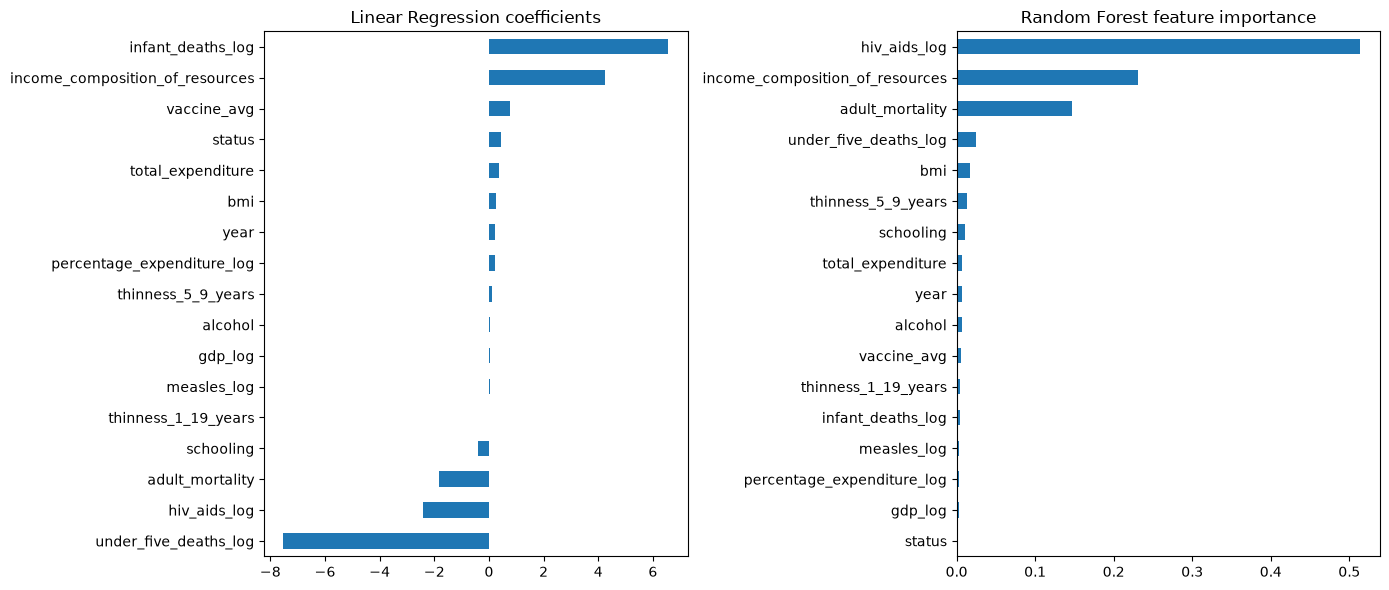

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

pd.Series(lin_pipe.named_steps['model'].coef_, index=X.columns).sort_values().plot(
    kind='barh', ax=axes[0], title='Linear Regression coefficients')

pd.Series(rf_pipe.named_steps['model'].feature_importances_, index=X.columns).sort_values().plot(
    kind='barh', ax=axes[1], title='Random Forest feature importance')

plt.tight_layout()
plt.show()

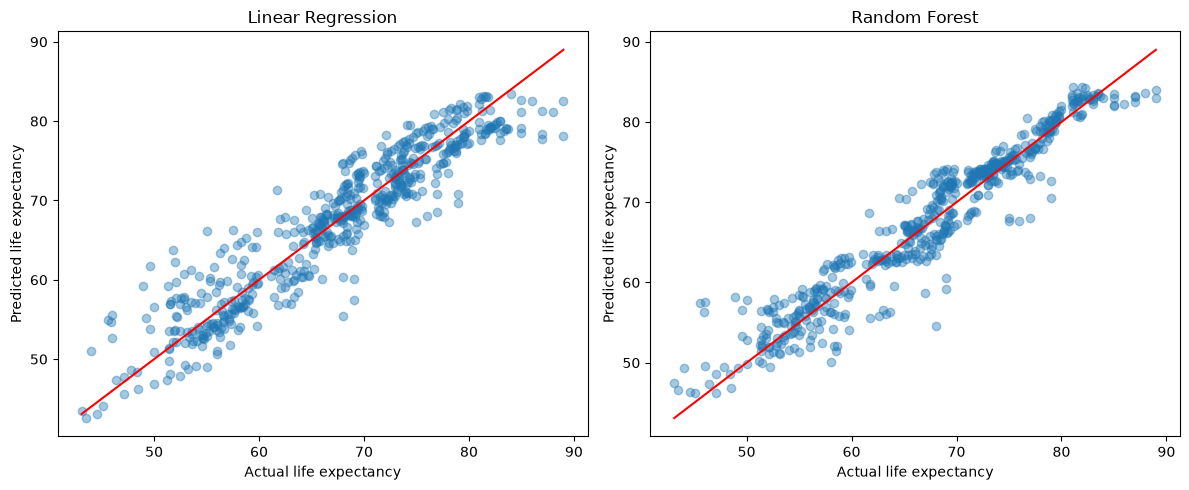

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pipe) in zip(axes, [('Linear Regression', lin_pipe), ('Random Forest', rf_pipe)]):
    pred = pipe.predict(X_test)
    ax.scatter(Y_test, pred, alpha=0.4)
    ax.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red')
    ax.set_xlabel('Actual life expectancy')
    ax.set_ylabel('Predicted life expectancy')
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [31]:
results = pd.DataFrame([res_lin, res_rf]).set_index('Model')
results.round(3)

,MAE,RMSE,R2
Model,,,
Linear Regression,2.666,3.460,0.872
Random Forest,2.011,2.759,0.919


In [32]:
gkf = GroupKFold(n_splits=5)

cv_lin = cross_val_score(lin_pipe, X, Y, cv=gkf, groups=groups, scoring='r2')
cv_rf = cross_val_score(rf_pipe, X, Y, cv=gkf, groups=groups, scoring='r2')

print('Linear Regression R2 per fold:', cv_lin.round(3), ' mean =', cv_lin.mean().round(3))
print('Random Forest     R2 per fold:', cv_rf.round(3), ' mean =', cv_rf.mean().round(3))

Linear Regression R2 per fold: [0.904 0.868 0.854 0.832 0.781]  mean = 0.848
Random Forest     R2 per fold: [0.94  0.916 0.9   0.897 0.872]  mean = 0.905


In [33]:
print(X.shape)
print(list(X.columns))

(2928, 17)
['year', 'status', 'adult_mortality', 'alcohol', 'bmi', 'total_expenditure', 'thinness_1_19_years', 'thinness_5_9_years', 'income_composition_of_resources', 'schooling', 'vaccine_avg', 'measles_log', 'infant_deaths_log', 'under_five_deaths_log', 'gdp_log', 'percentage_expenditure_log', 'hiv_aids_log']


In [34]:
pipes = {'Linear Regression': lin_pipe, 'Random Forest': rf_pipe,
         'KNN': knn_pipe, 'SVR': svr_pipe}

rows = []
for name, pipe in pipes.items():
    pipe.fit(X_train, Y_train)
    pred = pipe.predict(X_test)
    cv = cross_val_score(pipe, X, Y, cv=GroupKFold(n_splits=5), groups=groups, scoring='r2')
    rows.append({'Model': name,
                 'MAE': mean_absolute_error(Y_test, pred),
                 'RMSE': np.sqrt(mean_squared_error(Y_test, pred)),
                 'R2': r2_score(Y_test, pred),
                 'CV_R2': cv.mean()})

results = pd.DataFrame(rows).set_index('Model').round(3)
results

,MAE,RMSE,R2,CV_R2
Model,,,,
Linear Regression,2.666,3.460,0.872,0.848
Random Forest,2.011,2.759,0.919,0.905
KNN,3.099,3.907,0.837,0.829
SVR,2.197,2.872,0.912,0.893


In [35]:
best_name = results['CV_R2'].idxmax()
print('Winner:', best_name)

Winner: Random Forest


In [36]:
import joblib

best_pipe = pipes[best_name]
best_pipe.fit(X, Y)

raw_cols = ['year', 'adult_mortality', 'alcohol', 'bmi', 'total_expenditure',
            'thinness_1_19_years', 'thinness_5_9_years', 'income_composition_of_resources',
            'schooling', 'hepatitis_b', 'polio', 'diphtheria', 'measles', 'infant_deaths',
            'under_five_deaths', 'gdp', 'percentage_expenditure', 'hiv_aids']
ranges = df[raw_cols].agg(['min', 'median', 'max']).to_dict()

joblib.dump({'model': best_pipe,
             'features': list(X.columns),
             'model_name': best_name,
             'ranges': ranges},
            'life_expectancy_model.joblib')
print('Saved')

Saved


In [37]:
loaded = joblib.load('life_expectancy_model.joblib')
print(loaded['model_name'], '|', len(loaded['features']), 'features')
print('Prediction:', loaded['model'].predict(X.iloc[[2]]), '| Actual:', Y.iloc[2])

Random Forest | 17 features
Prediction: [58.0935] | Actual: 56.2


In [38]:
results.to_csv('model_results.csv')

In [39]:
df.to_csv('life_expectancy_cleaned.csv', index=False)

In [40]:
print(df['life_expectancy'].describe())
print(loaded['model_name'])

count    2928.000000
mean       69.224932
std         9.523867
min        36.300000
25%        63.100000
50%        72.100000
75%        75.700000
max        89.000000
Name: life_expectancy, dtype: float64
Random Forest
